<a href="https://colab.research.google.com/github/yongmeiwang/AI_BigData_CancerBiology/blob/main/Oct13_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/yongmeiwang/AI_BigData_CancerBiology/main/Data/gtex_integrin_7_organs.xlsx"

Gtex_integrin = pd.read_excel(url)

Gtex_integrin.head()

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050


In [ ]:
Gtex_integrin.shape

(1987, 29)

In [2]:
Gtex_lung_brain=Gtex_integrin[Gtex_integrin['primary_site'].isin(['Lung','Brain'])]
Gtex_lung_brain.head()

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
5,GTEX-11EI6-0826-SM-5985V,Lung,6.0732,-2.4659,3.9901,7.3945,4.7688,5.1157,4.3356,2.3366,...,3.7378,4.7247,7.5016,5.1396,2.5036,6.5443,4.6531,3.8136,5.8679,0.7407
6,GTEX-S341-0326-SM-2XCAU,Lung,4.2510,-5.0116,3.3076,6.1715,3.1129,5.2954,2.2960,1.1184,...,4.7104,2.7530,7.5022,4.0730,2.6325,6.0483,5.0562,2.6962,5.1611,0.9343


In [3]:
Gtex_lung_brain.shape

(1440, 29)

In [ ]:
Gtex_lung_brain['primary_site'].unique()

array(['Brain', 'Lung'], dtype=object)

In [ ]:
Gtex_lung_brain['primary_site'].values

array(['Brain', 'Lung', 'Lung', ..., 'Lung', 'Brain', 'Lung'],
      dtype=object)

In [ ]:
Gtex_lung_brain['primary_site'].value_counts()

,count
primary_site,
Brain,1152
Lung,288


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
integrins = [col for col in Gtex_lung_brain.columns if col.startswith("ITG")]
# Integrin columns = all columns except Primary Site

# Convert from wide to long format
df_long = Gtex_lung_brain.melt(
    id_vars="primary_site",
    value_vars=integrins,
    var_name="Integrin",
    value_name="Expression"
)


In [5]:
df_long.head()

,primary_site,Integrin,Expression
0,Brain,ITGA10,0.5763
1,Lung,ITGA10,4.9137
2,Lung,ITGA10,4.0541
3,Lung,ITGA10,6.0732
4,Lung,ITGA10,4.2510


<Figure size 1800x700 with 0 Axes>

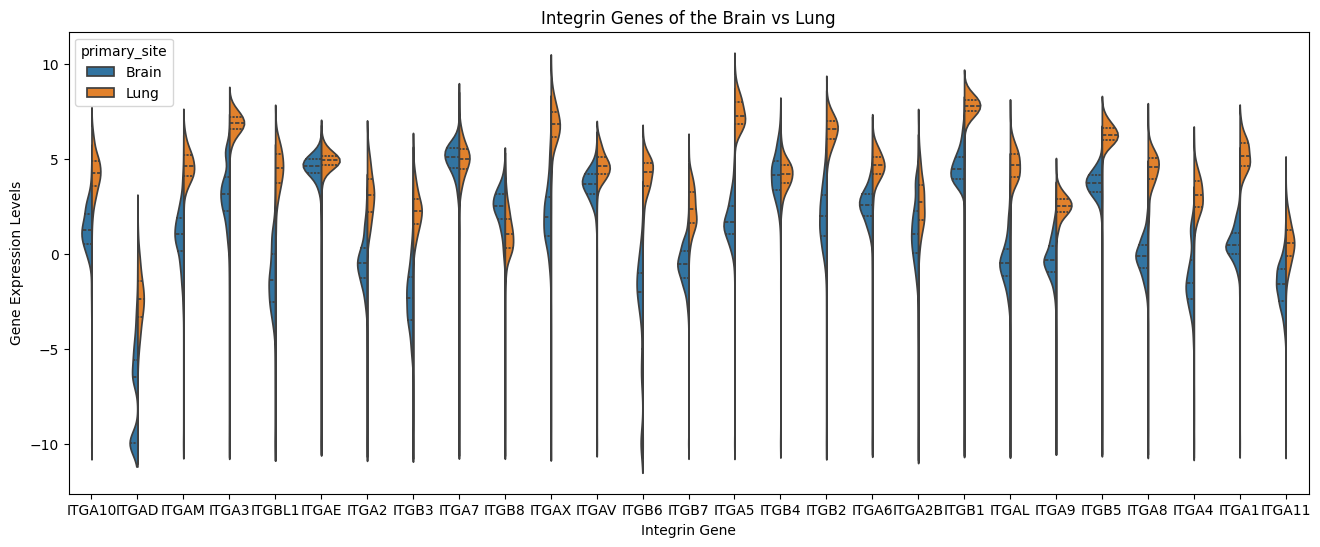

<Figure size 640x480 with 0 Axes>

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(18, 7))
plt.figure(figsize=(16, 6))
sns.violinplot(x = 'Integrin', y = 'Expression', hue = 'primary_site', data = df_long, split = True, inner = 'quartile')
plt.title("Integrin Genes of the Brain vs Lung")
plt.xlabel("Integrin Gene")
plt.ylabel("Gene Expression Levels")
plt.legend(title = 'primary_site')
plt.show()


plt.tight_layout()
plt.show()

In [8]:
# develop a logistic regression using ITGA10 expression.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X = Gtex_lung_brain[["ITGA10"]]

y = Gtex_lung_brain["primary_site"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42) #70% training data, 30% testing data

model = LogisticRegression()

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.9398148148148148


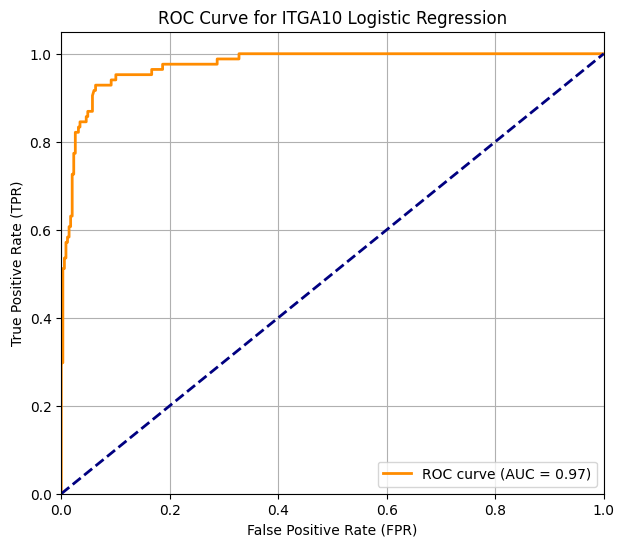

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (Lung)
y_score = model.predict_proba(X_test)[:, 1]

# Map target labels to binary values (Brain = 0, Lung = 1)
y_test_binary = y_test.map({'Brain': 0, 'Lung': 1})

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test_binary, y_score)
auc_score = roc_auc_score(y_test_binary, y_score)

# Plot the ROC Curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for ITGA10 Logistic Regression')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Accuracy with ITGAV: 0.8380


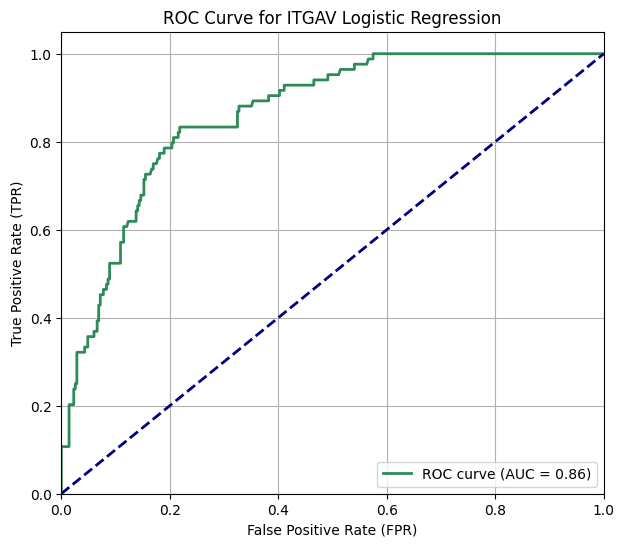

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prepare feature matrix X using ITGAV and target vector y
X_itgav = Gtex_lung_brain[['ITGAV']]
y_itgav = Gtex_lung_brain['primary_site']

# Split into training and testing sets
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_itgav, y_itgav, test_size=0.3, random_state=42)

# Initialize and fit the logistic regression model
model_itgav = LogisticRegression()
model_itgav.fit(X_train_v, y_train_v)

# Get accuracy
y_pred_v = model_itgav.predict(X_test_v)
accuracy_v = accuracy_score(y_test_v, y_pred_v)
print(f"Accuracy with ITGAV: {accuracy_v:.4f}")

# Get predicted probabilities for the positive class (Lung)
y_score_v = model_itgav.predict_proba(X_test_v)[:, 1]

# Map target labels to binary values
y_test_v_binary = y_test_v.map({'Brain': 0, 'Lung': 1})

# Calculate ROC values
fpr_v, tpr_v, thresholds_v = roc_curve(y_test_v_binary, y_score_v)
auc_score_v = roc_auc_score(y_test_v_binary, y_score_v)

# Plot the ROC Curve for ITGAV
plt.figure(figsize=(7, 6))
plt.plot(fpr_v, tpr_v, color='seagreen', lw=2, label=f'ROC curve (AUC = {auc_score_v:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for ITGAV Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [24]:
threshold_ITGAV = -model.intercept_[0] / model.coef_[0][0]

print("ITGAV expression threshold:", threshold_ITGAV)

ITGAV expression threshold: 3.362515601860963


In [26]:
beta0 = model.intercept_[0]
beta1 = model.coef_[0][0]

print("β0 (intercept):", beta0)
print("β1 (ITGAV coefficient):", beta1)

β0 (intercept): -7.129426424318513
β1 (ITGAV coefficient): 2.120265678580875


P(Brain) = 1 / (1 + exp(-(-8.4241 + 1.6994 * x)))


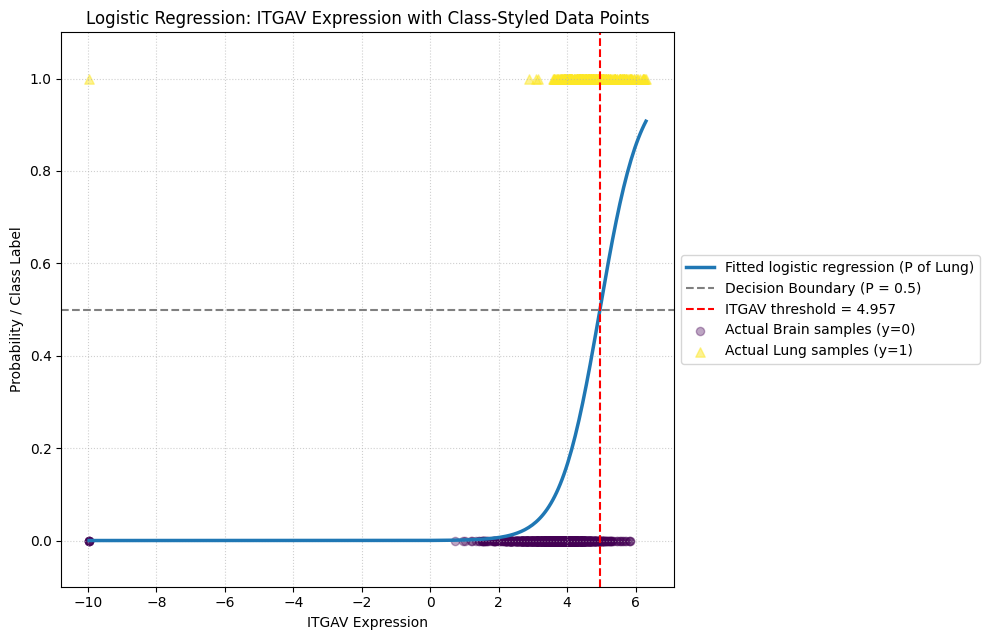

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

# Fitted parameters from the ITGAV model
beta0 = model_itgav.intercept_[0]
beta1 = model_itgav.coef_[0][0]

# Print fitted equation
print(f"P(Brain) = 1 / (1 + exp(-({beta0:.4f} + {beta1:.4f} * x)))")

# Generate ITGAV expression values for the smooth sigmoid curve
x = np.linspace(Gtex_lung_brain["ITGAV"].min(), Gtex_lung_brain["ITGAV"].max(), 300)

# Compute probability using fitted logistic function
p = expit(beta0 + beta1 * x)

# Plot
plt.figure(figsize=(10, 6.5))
plt.plot(x, p, linewidth=2.5, color="tab:blue", label="Fitted logistic regression (P of Lung)")
plt.axhline(0.5, color="gray", linestyle="--", label="Decision Boundary (P = 0.5)")

# Mark ITGAV expression threshold
x_threshold = -beta0 / beta1
plt.axvline(x_threshold, color="red", linestyle="--",
            label=f"ITGAV threshold = {x_threshold:.3f}")

# Separate Brain (y=0) and Lung (y=1) data points
brain_data = Gtex_lung_brain[Gtex_lung_brain["primary_site"] == 'Brain']
lung_data = Gtex_lung_brain[Gtex_lung_brain["primary_site"] == 'Lung']

# Plot Brain points at y=0 (Blueish-purple, circle, slightly lower alpha or jitter if preferred)
plt.scatter(brain_data["ITGAV"], np.zeros(len(brain_data)), alpha=0.35,
            color="#440154FF", marker="o", s=35, label="Actual Brain samples (y=0)")

# Plot Lung points at y=1 (Yellow/Gold, triangle, slightly lower alpha)
plt.scatter(lung_data["ITGAV"], np.ones(len(lung_data)), alpha=0.5,
            color="#FDE725FF", marker="^", s=45, label="Actual Lung samples (y=1)")

plt.xlabel("ITGAV Expression")
plt.ylabel("Probability / Class Label")
plt.title("Logistic Regression: ITGAV Expression with Class-Styled Data Points")
plt.ylim(-0.1, 1.1)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [31]:
# Calculate min and max ITGAV expression for Brain
brain_itgav = Gtex_lung_brain[Gtex_lung_brain['primary_site'] == 'Brain']['ITGAV']
brain_min, brain_max = brain_itgav.min(), brain_itgav.max()

# Calculate min and max ITGAV expression for Lung
lung_itgav = Gtex_lung_brain[Gtex_lung_brain['primary_site'] == 'Lung']['ITGAV']
lung_min, lung_max = lung_itgav.min(), lung_itgav.max()

print(f"Brain ITGAV expression: Min = {brain_min:.4f}, Max = {brain_max:.4f}")
print(f"Lung ITGAV expression: Min = {lung_min:.4f}, Max = {lung_max:.4f}")

Brain ITGAV expression: Min = -9.9658, Max = 5.8230
Lung ITGAV expression: Min = -9.9658, Max = 6.3014


Accuracy with ITGAE: 0.8056


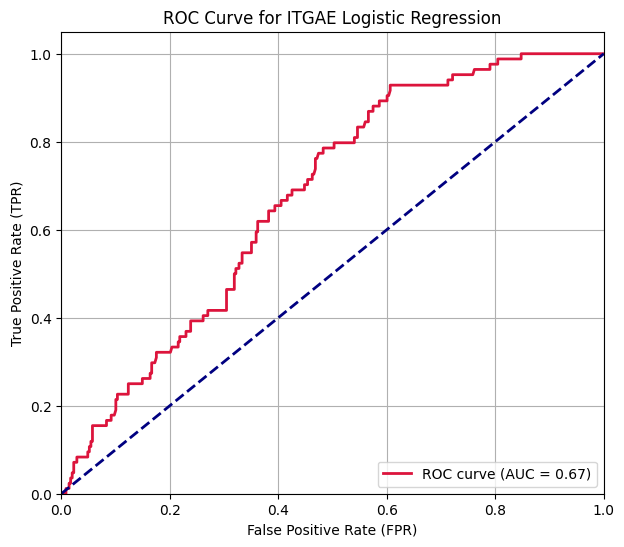

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prepare feature matrix X using ITGAE and target vector y
X_itgae = Gtex_lung_brain[['ITGAE']]
y_itgae = Gtex_lung_brain['primary_site']

# Split into training and testing sets
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_itgae, y_itgae, test_size=0.3, random_state=42)

# Initialize and fit the logistic regression model
model_itgae = LogisticRegression()
model_itgae.fit(X_train_e, y_train_e)

# Get accuracy
y_pred_e = model_itgae.predict(X_test_e)
accuracy_e = accuracy_score(y_test_e, y_pred_e)
print(f"Accuracy with ITGAE: {accuracy_e:.4f}")

# Get predicted probabilities for the positive class (Lung)
y_score_e = model_itgae.predict_proba(X_test_e)[:, 1]

# Map target labels to binary values
y_test_e_binary = y_test_e.map({'Brain': 0, 'Lung': 1})

# Calculate ROC values
fpr_e, tpr_e, thresholds_e = roc_curve(y_test_e_binary, y_score_e)
auc_score_e = roc_auc_score(y_test_e_binary, y_score_e)

# Plot the ROC Curve for ITGAE
plt.figure(figsize=(7, 6))
plt.plot(fpr_e, tpr_e, color='crimson', lw=2, label=f'ROC curve (AUC = {auc_score_e:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for ITGAE Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Accuracy with ITGAE + ITGAV: 0.8403


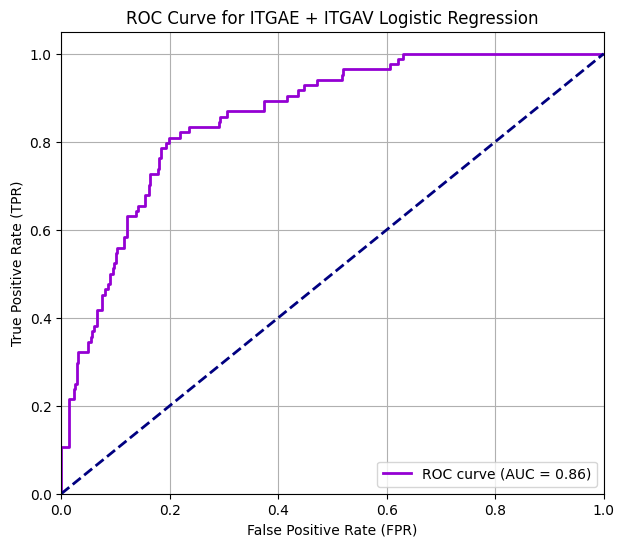

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prepare feature matrix X using both ITGAE and ITGAV
X_both = Gtex_lung_brain[['ITGAE', 'ITGAV']]
y_both = Gtex_lung_brain['primary_site']

# Split into training and testing sets
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_both, y_both, test_size=0.3, random_state=42)

# Initialize and fit the logistic regression model
model_both = LogisticRegression()
model_both.fit(X_train_b, y_train_b)

# Get accuracy
y_pred_b = model_both.predict(X_test_b)
accuracy_b = accuracy_score(y_test_b, y_pred_b)
print(f"Accuracy with ITGAE + ITGAV: {accuracy_b:.4f}")

# Get predicted probabilities for the positive class (Lung)
y_score_b = model_both.predict_proba(X_test_b)[:, 1]

# Map target labels to binary values
y_test_b_binary = y_test_b.map({'Brain': 0, 'Lung': 1})

# Calculate ROC values
fpr_b, tpr_b, thresholds_b = roc_curve(y_test_b_binary, y_score_b)
auc_score_b = roc_auc_score(y_test_b_binary, y_score_b)

# Plot the ROC Curve for the combined model
plt.figure(figsize=(7, 6))
plt.plot(fpr_b, tpr_b, color='darkviolet', lw=2, label=f'ROC curve (AUC = {auc_score_b:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve for ITGAE + ITGAV Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

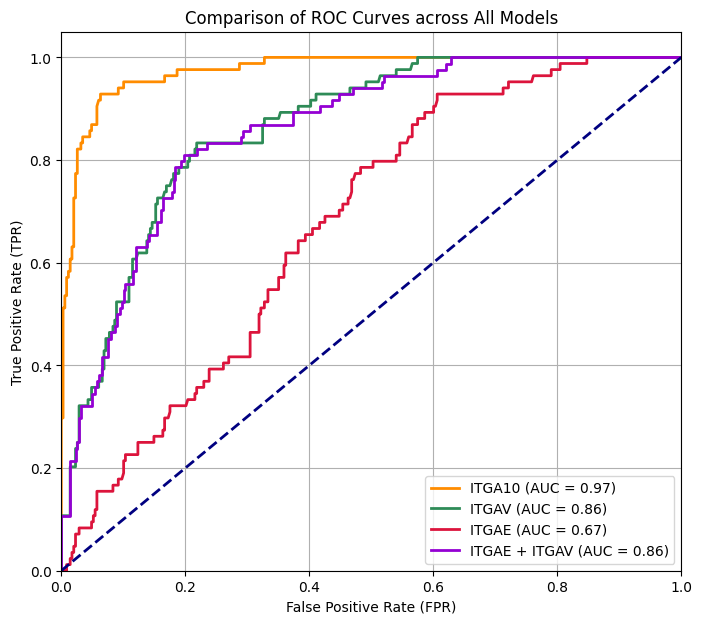

In [14]:
plt.figure(figsize=(8, 7))

# Plot ITGA10
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ITGA10 (AUC = {auc_score:.2f})')

# Plot ITGAV
plt.plot(fpr_v, tpr_v, color='seagreen', lw=2, label=f'ITGAV (AUC = {auc_score_v:.2f})')

# Plot ITGAE
plt.plot(fpr_e, tpr_e, color='crimson', lw=2, label=f'ITGAE (AUC = {auc_score_e:.2f})')

# Plot ITGAE + ITGAV
plt.plot(fpr_b, tpr_b, color='darkviolet', lw=2, label=f'ITGAE + ITGAV (AUC = {auc_score_b:.2f})')

# Plot reference diagonal line
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Comparison of ROC Curves across All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [15]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
import numpy as np

# We will use StratifiedKFold to maintain the target class distribution across folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Map the target variable to binary values for AUC score calculation
y_binary = y.map({'Brain': 0, 'Lung': 1})

# Initialize the model
cv_model = LogisticRegression()

# Perform 5-Fold cross-validation using ROC AUC as the metric
auc_scores = cross_val_score(cv_model, X, y_binary, cv=cv, scoring='roc_auc')

print("ROC AUC scores for each fold:", [f"{score:.4f}" for score in auc_scores])
print(f"Mean ROC AUC: {np.mean(auc_scores):.4f}")
print(f"Standard Deviation: {np.std(auc_scores):.4f}")

ROC AUC scores for each fold: ['0.9576', '0.9846', '0.9568', '0.9729', '0.9657']
Mean ROC AUC: 0.9675
Standard Deviation: 0.0103


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Safely define the integrin column list from the dataframe columns
integrins = [col for col in Gtex_lung_brain.columns if col.startswith("ITG")]
print(f"Found {len(integrins)} integrin features: {integrins}")

# Prepare the feature matrix X with all integrin columns
X_all = Gtex_lung_brain[integrins]
y_all = Gtex_lung_brain['primary_site']

# Split into training and testing sets (70% train, 30% test)
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42
)

# Initialize and train the Random Forest model
rf_model_all = RandomForestClassifier(random_state=42)
rf_model_all.fit(X_train_all, y_train_all)

# Evaluate accuracy
y_pred_rf_all = rf_model_all.predict(X_test_all)
accuracy_rf_all = accuracy_score(y_test_all, y_pred_rf_all)

# Get predicted probabilities for the positive class (Lung)
y_score_rf_all = rf_model_all.predict_proba(X_test_all)[:, 1]
y_test_all_binary = y_test_all.map({'Brain': 0, 'Lung': 1})

# Calculate ROC values
fpr_rf_all, tpr_rf_all, thresholds_rf_all = roc_curve(y_test_all_binary, y_score_rf_all)
auc_score_rf_all = roc_auc_score(y_test_all_binary, y_score_rf_all)

print(f"\nRandom Forest (All Integrins) Accuracy: {accuracy_rf_all:.4f}")
print(f"Random Forest (All Integrins) AUC: {auc_score_rf_all:.4f}")

Found 27 integrin features: ['ITGA10', 'ITGAD', 'ITGAM', 'ITGA3', 'ITGBL1', 'ITGAE', 'ITGA2', 'ITGB3', 'ITGA7', 'ITGB8', 'ITGAX', 'ITGAV', 'ITGB6', 'ITGB7', 'ITGA5', 'ITGB4', 'ITGB2', 'ITGA6', 'ITGA2B', 'ITGB1', 'ITGAL', 'ITGA9', 'ITGB5', 'ITGA8', 'ITGA4', 'ITGA1', 'ITGA11']

Random Forest (All Integrins) Accuracy: 0.9954
Random Forest (All Integrins) AUC: 1.0000
